# Who are the primary clients?
This notebook builds a profile of the clients in the experiment using gender, number of accounts, balance, and online/phone activity.

## Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load the cleaned data
Reads the 3 cleaned CSV files from `01_data_cleaning.ipynb` (experiment clients only), renames `Variation` to `variation`, and builds `df_clients` (demographics + test group) and `df_web_exp` (web events + test group).

In [2]:
clients_demo = pd.read_csv('02_cleaned_data_files/cleaned_clients_demographics.csv')
clients_var = pd.read_csv('02_cleaned_data_files/cleaned_clients_variation.csv')
web_events = pd.read_csv('02_cleaned_data_files/cleaned_web_events.csv', parse_dates=['date_time'])

clients_var = clients_var.rename(columns={'Variation': 'variation'})

df_clients = clients_var.merge(clients_demo, on='client_id', how='inner')
df_web_exp = web_events.merge(clients_var, on='client_id', how='inner')

In [3]:
df_clients.head()

,client_id,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,9988021,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0
1,8320017,Test,22.0,274.0,34.5,M,2.0,36001.90,5.0,8.0
2,4033851,Control,12.0,149.0,63.5,M,2.0,142642.26,5.0,8.0
3,1982004,Test,6.0,80.0,44.5,U,2.0,30231.76,1.0,4.0
4,9294070,Control,5.0,70.0,29.0,U,2.0,34254.54,0.0,3.0


## 1. Gender

In [4]:
df_clients['gendr'].value_counts(normalize=True)

gendr
U    0.342299
M    0.335664
F    0.322037
Name: proportion, dtype: float64

In [5]:
gender_pct = df_clients['gendr'].value_counts(normalize=True) * 100
gender_pct

gendr
U    34.229916
M    33.566392
F    32.203692
Name: proportion, dtype: float64

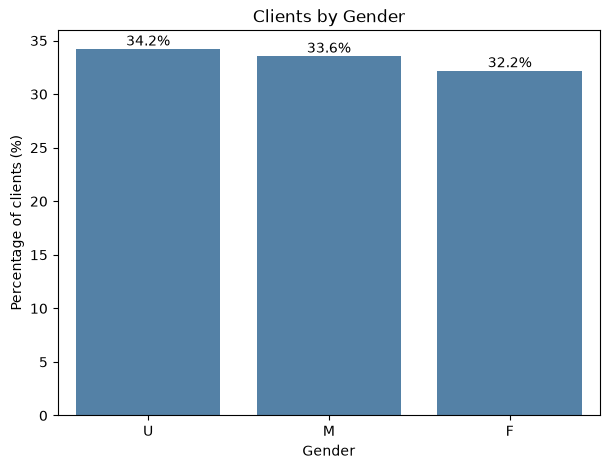

In [6]:
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=gender_pct.index, y=gender_pct.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title("Clients by Gender")
plt.ylabel("Percentage of clients (%)")
plt.xlabel("Gender")
plt.show()

Gender is almost evenly split between male (33.6%) and female (32.2%) clients. However, 34.2% of clients have an unknown gender, so we cannot draw a strong conclusion about gender.

## 2. Number of accounts

In [7]:
df_clients['num_accts'].value_counts(normalize=True)

num_accts
2.0    0.786741
3.0    0.177210
4.0    0.031394
5.0    0.004060
6.0    0.000456
7.0    0.000119
1.0    0.000020
Name: proportion, dtype: float64

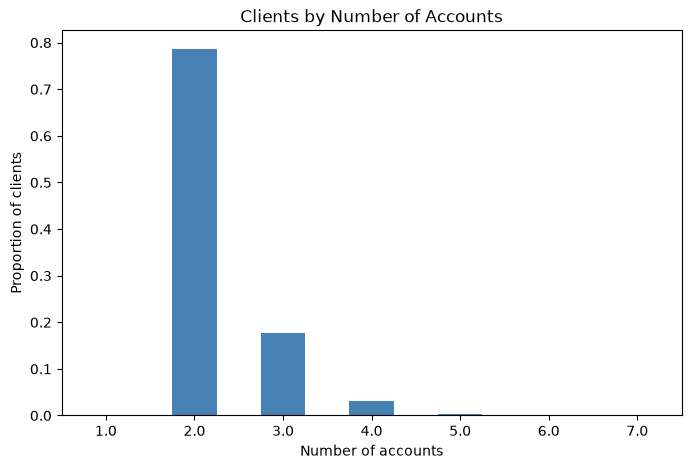

In [8]:
accts_pct = df_clients['num_accts'].value_counts(normalize=True).sort_index()

accts_pct.plot(kind='bar', color='steelblue', figsize=(8, 5))

plt.title('Clients by Number of Accounts')
plt.xlabel('Number of accounts')
plt.ylabel('Proportion of clients')
plt.xticks(rotation=0)
plt.show()

Most clients (about 79%) hold 2 accounts, and almost all (about 96%) hold 2 or 3 accounts. Clients with only 1 account are extremely rare.

## 3. Balance

In [9]:
pd.set_option('display.float_format', '{:,.0f}'.format)

In [10]:
df_clients['bal'].describe()

count       50,488
mean       149,515
std        302,036
min         23,789
25%         39,878
50%         65,734
75%        139,957
max     16,320,040
Name: bal, dtype: float64

The typical client has a balance of about 65,700 (median). The mean (about 149,500) is more than twice the median because a small number of very wealthy clients (up to 16.3 million) pull it up, so the median is a better measure here.

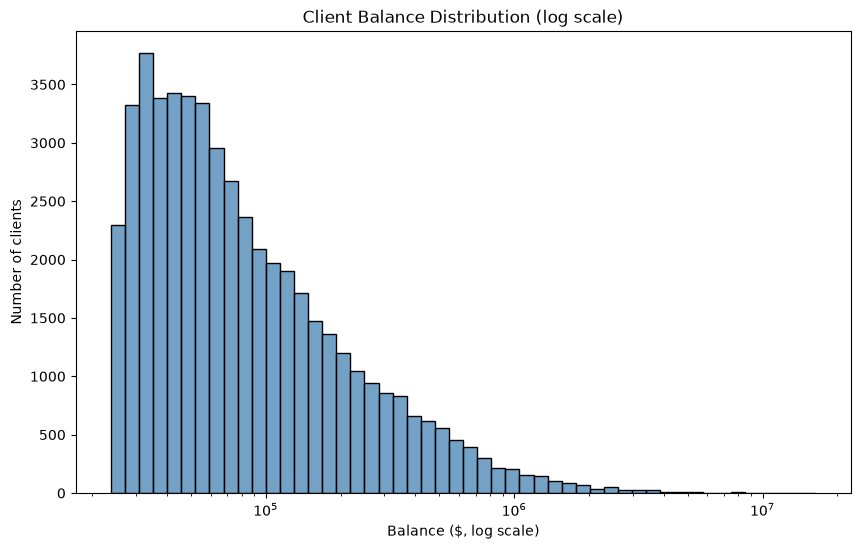

In [11]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clients['bal'], bins=50, log_scale=True, color="steelblue")
plt.title("Client Balance Distribution (log scale)")
plt.xlabel("Balance ($, log scale)")
plt.ylabel("Number of clients")
plt.show()

## 4. Online and phone activity

In [12]:
df_clients[['logons_6_mnth', 'calls_6_mnth']].describe()

,logons_6_mnth,calls_6_mnth
count,"50,488","50,488"
mean,6,3
std,2,2
min,3,0
25%,4,1
50%,6,3
75%,8,5
max,9,6


Clients are more active online than by phone: in the last 6 months, the typical client logged on 6 times and called 3 times. Every client logged on at least 3 times.

In [13]:
(df_clients['logons_6_mnth'] - df_clients['calls_6_mnth']).value_counts()

3    48836
4     1428
5      177
6       30
7       10
8        6
9        1
Name: count, dtype: int64

In [14]:
df_clients['logons_6_mnth'].corr(df_clients['calls_6_mnth'], method='pearson')

np.float64(0.9944469977697411)

In [15]:
df_clients['logons_6_mnth'].corr(df_clients['calls_6_mnth'], method='spearman')

np.float64(0.9940782159983262)

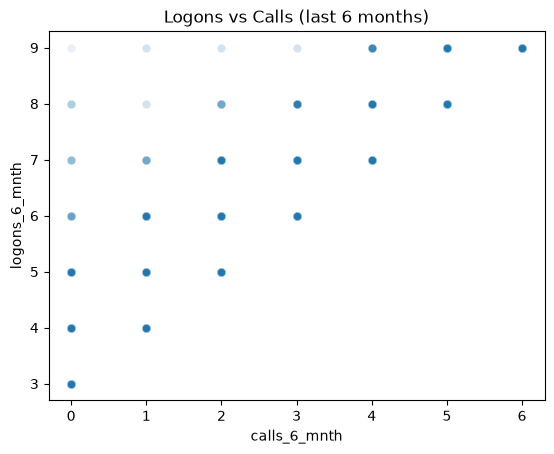

In [16]:
sns.scatterplot(data=df_clients, x='calls_6_mnth', y='logons_6_mnth', alpha=0.1)
plt.title('Logons vs Calls (last 6 months)')
plt.show()

Clients logged on 6 times and called 3 times in the last 6 months (median). Note: for about 97% of clients, logons are exactly calls + 3, which looks unusual and may be a data quality issue.

## Summary: primary client profile

Primary client profile: The typical client is middle-aged or older (more than half are 45+) and long-standing (over 80% have been clients for more than 5 years). Gender is evenly split between men and women, although about a third is unknown. Most clients hold 2 accounts and have a median balance of about 65,700. In the last 6 months, the typical client logged on about 6 times and called about 3 times.